In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from omegaconf import OmegaConf


In [2]:
config = OmegaConf.load("config.yaml")

target = config.data.target
id_col = config.data.id_column
train = pd.read_csv(config.data.train_path)
test = pd.read_csv(config.data.test_path)

In [7]:
num_cols = train.select_dtypes(include="number").columns.drop([id_col, target])
cat_cols = train.select_dtypes(exclude="number").columns
len(num_cols), len(cat_cols)

(36, 43)

In [7]:
train[num_cols].describe()

,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,BsmtFinSF2,...,GarageArea,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold
count,1460.000000,1201.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1452.000000,1460.000000,1460.000000,...,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,56.897260,70.049958,10516.828082,6.099315,5.575342,1971.267808,1984.865753,103.685262,443.639726,46.549315,...,472.980137,94.244521,46.660274,21.954110,3.409589,15.060959,2.758904,43.489041,6.321918,2007.815753
std,42.300571,24.284752,9981.264932,1.382997,1.112799,30.202904,20.645407,181.066207,456.098091,161.319273,...,213.804841,125.338794,66.256028,61.119149,29.317331,55.757415,40.177307,496.123024,2.703626,1.328095
min,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000
25%,20.000000,59.000000,7553.500000,5.000000,5.000000,1954.000000,1967.000000,0.000000,0.000000,0.000000,...,334.500000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2007.000000
50%,50.000000,69.000000,9478.500000,6.000000,5.000000,1973.000000,1994.000000,0.000000,383.500000,0.000000,...,480.000000,0.000000,25.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000
75%,70.000000,80.000000,11601.500000,7.000000,6.000000,2000.000000,2004.000000,166.000000,712.250000,0.000000,...,576.000000,168.000000,68.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000
max,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,5644.000000,1474.000000,...,1418.000000,857.000000,547.000000,552.000000,508.000000,480.000000,738.000000,15500.000000,12.000000,2010.000000


In [9]:
train[cat_cols].describe()

,MSZoning,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,...,GarageType,GarageFinish,GarageQual,GarageCond,PavedDrive,PoolQC,Fence,MiscFeature,SaleType,SaleCondition
count,1460,1460,91,1460,1460,1460,1460,1460,1460,1460,...,1379,1379,1379,1379,1460,7,281,54,1460,1460
unique,5,2,2,4,4,2,5,3,25,9,...,6,3,5,5,3,3,4,4,9,6
top,RL,Pave,Grvl,Reg,Lvl,AllPub,Inside,Gtl,NAmes,Norm,...,Attchd,Unf,TA,TA,Y,Gd,MnPrv,Shed,WD,Normal
freq,1151,1454,50,925,1311,1459,1052,1382,225,1260,...,870,605,1311,1326,1340,3,157,49,1267,1198


### Анализ пропусков

In [5]:
missing = pd.DataFrame({
    "train_count": train.isna().sum(),
    "train_share": train.isna().mean(),
    "test_count": test.isna().sum(),
    "test_share": test.isna().mean(),
})
missing[missing.sum(axis=1) > 0].sort_values("train_count", ascending=False)

,train_count,train_share,test_count,test_share
PoolQC,1453,0.995205,1456.0,0.997944
MiscFeature,1406,0.963014,1408.0,0.965045
Alley,1369,0.937671,1352.0,0.926662
Fence,1179,0.807534,1169.0,0.801234
MasVnrType,872,0.597260,894.0,0.612748
FireplaceQu,690,0.472603,730.0,0.500343
LotFrontage,259,0.177397,227.0,0.155586
GarageFinish,81,0.055479,78.0,0.053461
GarageCond,81,0.055479,78.0,0.053461
GarageYrBlt,81,0.055479,78.0,0.053461


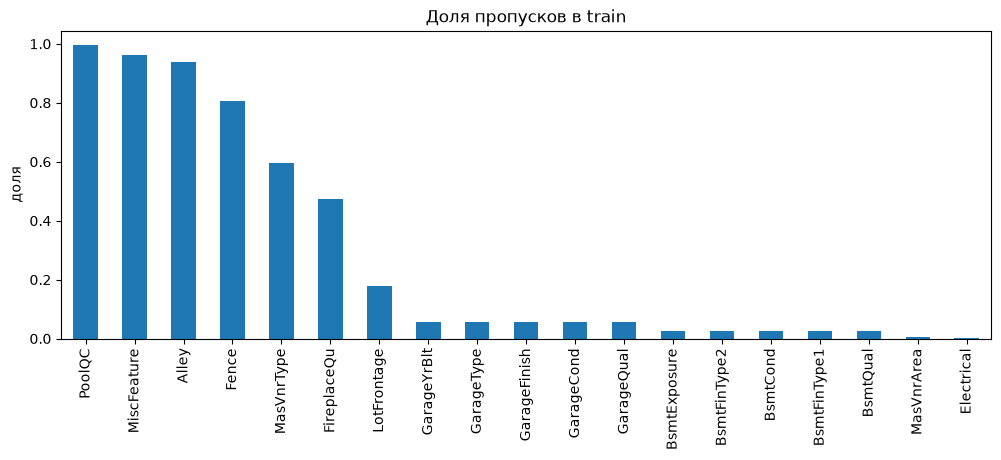

In [6]:
plt.figure(figsize=(12, 4))
missing.loc[missing["train_count"] > 0, "train_share"].sort_values(ascending=False).plot(kind="bar")
plt.title("Доля пропусков в train")
plt.ylabel("доля")
plt.show()

In [7]:
no_garage = train["GarageType"].isna()
train.loc[no_garage, ["GarageYrBlt", "GarageFinish", "GarageQual", "GarageCond", "GarageArea"]].describe(include="all")

,GarageYrBlt,GarageFinish,GarageQual,GarageCond,GarageArea
count,0.0,0,0,0,81.0
unique,NaN,0,0,0,NaN
top,NaN,NaN,NaN,NaN,NaN
freq,NaN,NaN,NaN,NaN,NaN
mean,NaN,NaN,NaN,NaN,0.0
std,NaN,NaN,NaN,NaN,0.0
min,NaN,NaN,NaN,NaN,0.0
25%,NaN,NaN,NaN,NaN,0.0
50%,NaN,NaN,NaN,NaN,0.0
75%,NaN,NaN,NaN,NaN,0.0


### Промежуточные выводы
- **Типы:** 36 числовых и 43 категориальных признака. `MSSubClass` записан числом, но это код типа дома, то есть категория.
- **Пропуски:** в train 19 столбцов, в test 33 (лишние 14 в test по 1–4 пропуска).
- **Пропуск = «объекта нет»:** `PoolQC`, `MiscFeature`, `Alley`, `Fence`, `FireplaceQu`, гаражные (`Garage*`) и подвальные (`Bsmt*`) столбцы. Проверено на гараже: у всех 81 дома без `GarageType` пусты остальные гаражные столбцы и `GarageArea` = 0.
- **`MasVnrType`:** значение `None` («облицовки нет») pandas читает как пропуск, поэтому пропусков 872, а не 8.
- **Настоящие пропуски:** `LotFrontage` (18%), `MasVnrArea`, `Electrical` и единичные пропуски в test.

### Анализируем таргет (цену)

In [3]:
train[target].describe()

count      1460.000000
mean     180921.195890
std       79442.502883
min       34900.000000
25%      129975.000000
50%      163000.000000
75%      214000.000000
max      755000.000000
Name: SalePrice, dtype: float64

In [4]:
train[target].skew(), np.log1p(train[target]).skew()

(np.float64(1.8828757597682129), np.float64(0.12134661989685333))

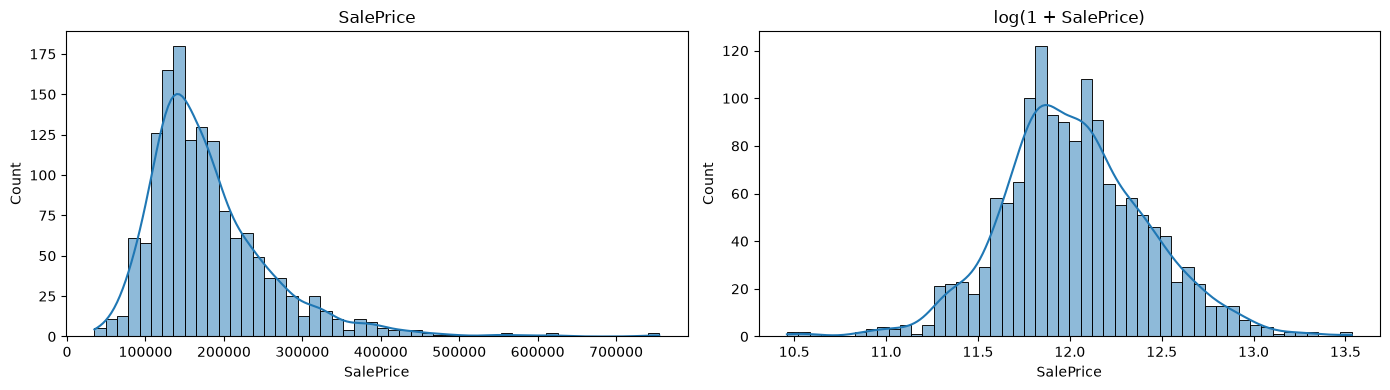

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

sns.histplot(train[target], bins=50, kde=True, ax=axes[0])
axes[0].set_title("SalePrice")

sns.histplot(np.log1p(train[target]), bins=50, kde=True, ax=axes[1])
axes[1].set_title("log(1 + SalePrice)")

plt.tight_layout()
plt.show()

### Промежуточные выводы
- **Цена:** медиана 163 000 \$, среднее 180 921 \$. Половина домов стоит 130–214 тыс. \$.
- **Распределение скошено вправо** (skew 1.88): мало очень дорогих домов с длинным хвостом.
- **После `log1p` распределение почти симметричное** (skew 0.12).
- **Решение:** учим модели на `log1p(SalePrice)`, а в сабмит пишем `expm1`. Так CV считается в той же шкале, что и метрика Kaggle (RMSE на логарифмах), и дорогие дома не перетягивают ошибку на себя.

### Корреляции

In [8]:
corr_target = train[num_cols].corrwith(np.log1p(train[target])).sort_values(ascending=False)
corr_target

OverallQual      0.817185
GrLivArea        0.700927
GarageCars       0.680625
GarageArea       0.650888
TotalBsmtSF      0.612134
1stFlrSF         0.596981
FullBath         0.594771
YearBuilt        0.586570
YearRemodAdd     0.565608
GarageYrBlt      0.541073
TotRmsAbvGrd     0.534422
Fireplaces       0.489450
MasVnrArea       0.430809
BsmtFinSF1       0.372023
LotFrontage      0.355879
WoodDeckSF       0.334135
OpenPorchSF      0.321053
2ndFlrSF         0.319300
HalfBath         0.313982
LotArea          0.257320
BsmtFullBath     0.236224
BsmtUnfSF        0.221985
BedroomAbvGr     0.209043
ScreenPorch      0.121208
PoolArea         0.069798
MoSold           0.057330
3SsnPorch        0.054900
BsmtFinSF2       0.004832
BsmtHalfBath    -0.005149
MiscVal         -0.020021
OverallCond     -0.036868
YrSold          -0.037263
LowQualFinSF    -0.037963
MSSubClass      -0.073959
KitchenAbvGr    -0.147548
EnclosedPorch   -0.149050
dtype: float64

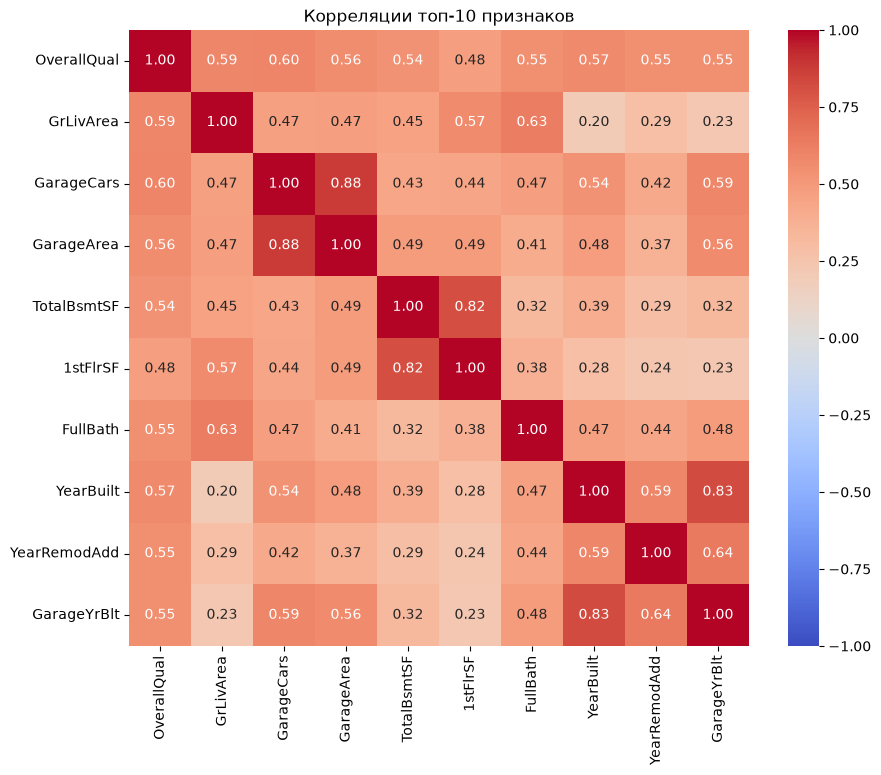

In [9]:
top10 = corr_target.abs().sort_values(ascending=False).head(10).index

plt.figure(figsize=(10, 8))
sns.heatmap(train[top10].corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Корреляции топ-10 признаков")
plt.show()

### Промежуточные выводы
- **Самые сильные признаки** (корреляция с `log1p(SalePrice)`): `OverallQual` 0.82, `GrLivArea` 0.70, `GarageCars` 0.68, `GarageArea` 0.65, `TotalBsmtSF` 0.61, затем год постройки и ремонта, ванные.
- **Слабые** (|r| < 0.1): `PoolArea`, `MoSold`, `YrSold`, `MiscVal`, `BsmtFinSF2`, `LowQualFinSF`, `OverallCond`.
- **Скоррелированные пары (> 0.8):** `GarageCars`–`GarageArea` 0.88, `YearBuilt`–`GarageYrBlt` 0.83, `GrLivArea`–`TotRmsAbvGrd` 0.83, `TotalBsmtSF`–`1stFlrSF` 0.82.

### Сильнейшие признаки и выбросы

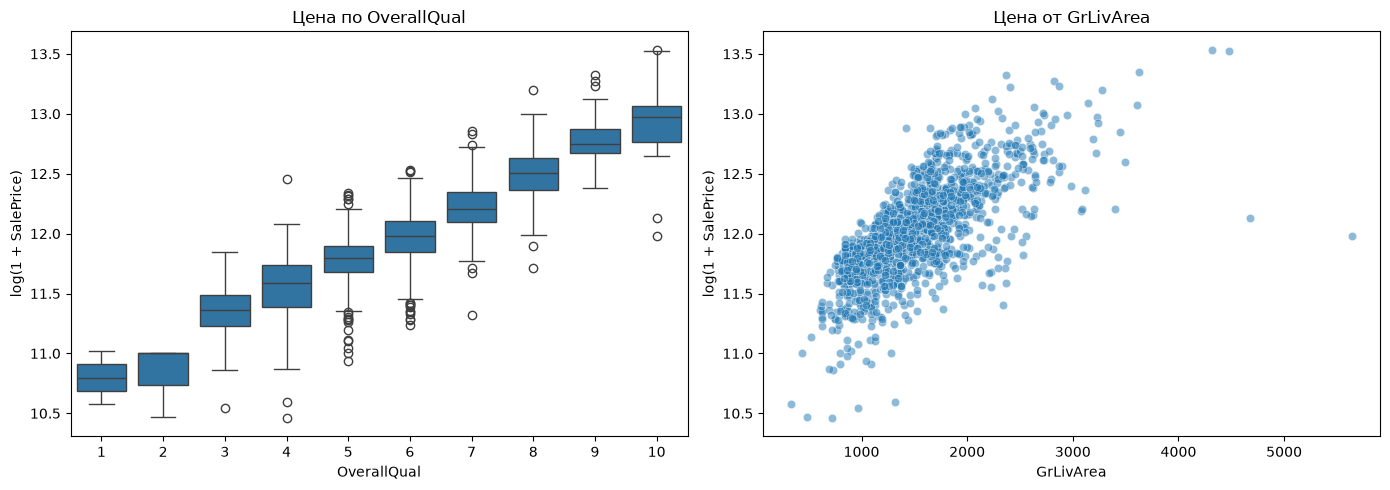

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(x=train["OverallQual"], y=np.log1p(train[target]), ax=axes[0])
axes[0].set_title("Цена по OverallQual")
axes[0].set_ylabel("log(1 + SalePrice)")

sns.scatterplot(x=train["GrLivArea"], y=np.log1p(train[target]), alpha=0.5, ax=axes[1])
axes[1].set_title("Цена от GrLivArea")
axes[1].set_ylabel("log(1 + SalePrice)")

plt.tight_layout()
plt.show()

In [11]:
outliers = train[(train["GrLivArea"] > 4000) & (train[target] < 300000)]
outliers[[id_col, "GrLivArea", "OverallQual", "SaleCondition", target]]

,Id,GrLivArea,OverallQual,SaleCondition,SalePrice
523,524,4676,10,Partial,184750
1298,1299,5642,10,Partial,160000


### Промежуточные выводы
- **`OverallQual`:** цена ровно растёт с качеством, медиана от 50 тыс. \$ (оценка 1) до 432 тыс. \$ (оценка 10). Главный признак.
- **`GrLivArea`:** чем больше жилая площадь, тем дороже, зависимость близка к линейной (в логарифме цены).
- **Выбросы:** 2 дома (Id 524, 1299) огромные (4676 и 5642 кв. футов) и высшего качества, но дешёвые (185 и 160 тыс. \$). Оба проданы недостроенными (`SaleCondition = Partial`), цена не отражает стоимость.

### Анализируем категориальные признаки

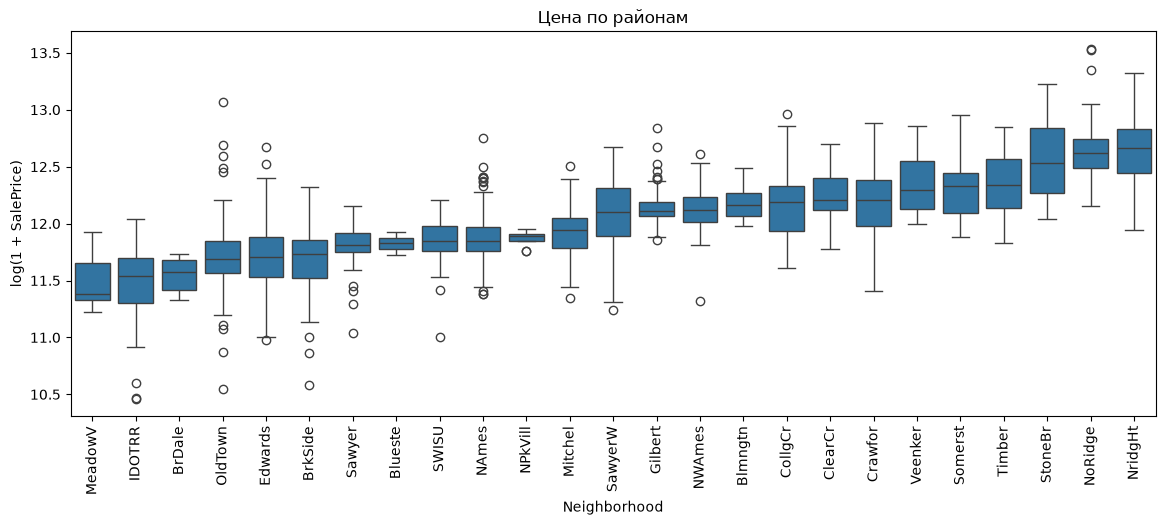

In [12]:
order = train.groupby("Neighborhood")[target].median().sort_values().index

plt.figure(figsize=(14, 5))
sns.boxplot(x=train["Neighborhood"], y=np.log1p(train[target]), order=order)
plt.xticks(rotation=90)
plt.title("Цена по районам")
plt.ylabel("log(1 + SalePrice)")
plt.show()

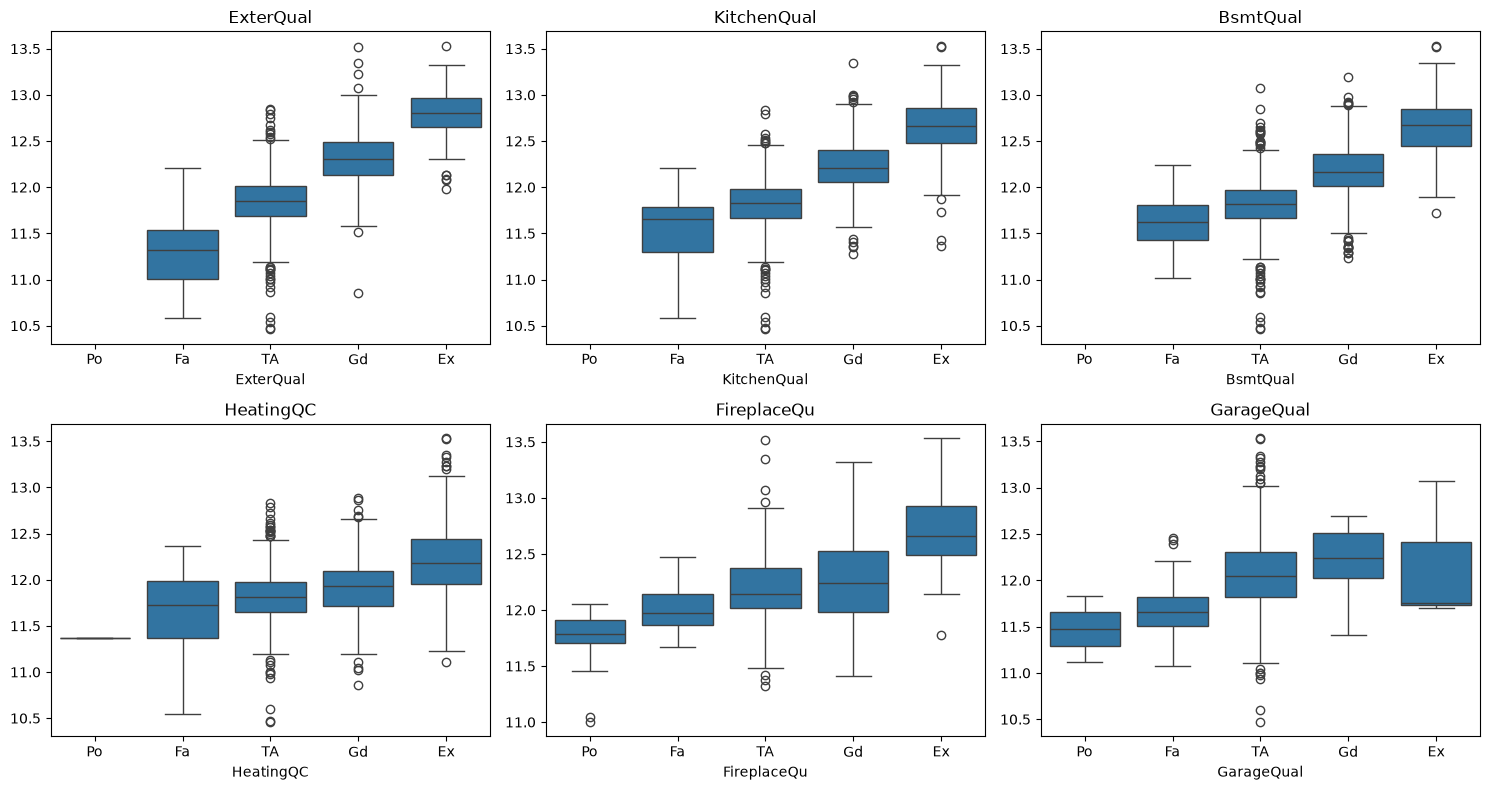

In [13]:
qual_cols = ["ExterQual", "KitchenQual", "BsmtQual", "HeatingQC", "FireplaceQu", "GarageQual"]
qual_order = ["Po", "Fa", "TA", "Gd", "Ex"]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flat, qual_cols):
    sns.boxplot(x=train[col], y=np.log1p(train[target]), order=qual_order, ax=ax)
    ax.set_title(col)
    ax.set_ylabel("")
plt.tight_layout()
plt.show()

In [14]:
top_share = train[cat_cols].apply(lambda s: s.value_counts(normalize=True, dropna=False).iloc[0])
top_share.sort_values(ascending=False).head(10)

Utilities      0.999315
Street         0.995890
PoolQC         0.995205
Condition2     0.989726
RoofMatl       0.982192
Heating        0.978082
MiscFeature    0.963014
LandSlope      0.946575
Alley          0.937671
CentralAir     0.934932
dtype: float64

### Скошенные признаки

In [15]:
skew = train[num_cols].skew().sort_values(ascending=False)
skew[skew > 0.75]

MiscVal          24.476794
PoolArea         14.828374
LotArea          12.207688
3SsnPorch        10.304342
LowQualFinSF      9.011341
KitchenAbvGr      4.488397
BsmtFinSF2        4.255261
ScreenPorch       4.122214
BsmtHalfBath      4.103403
EnclosedPorch     3.089872
MasVnrArea        2.669084
OpenPorchSF       2.364342
LotFrontage       2.163569
BsmtFinSF1        1.685503
WoodDeckSF        1.541376
TotalBsmtSF       1.524255
MSSubClass        1.407657
1stFlrSF          1.376757
GrLivArea         1.366560
BsmtUnfSF         0.920268
2ndFlrSF          0.813030
dtype: float64

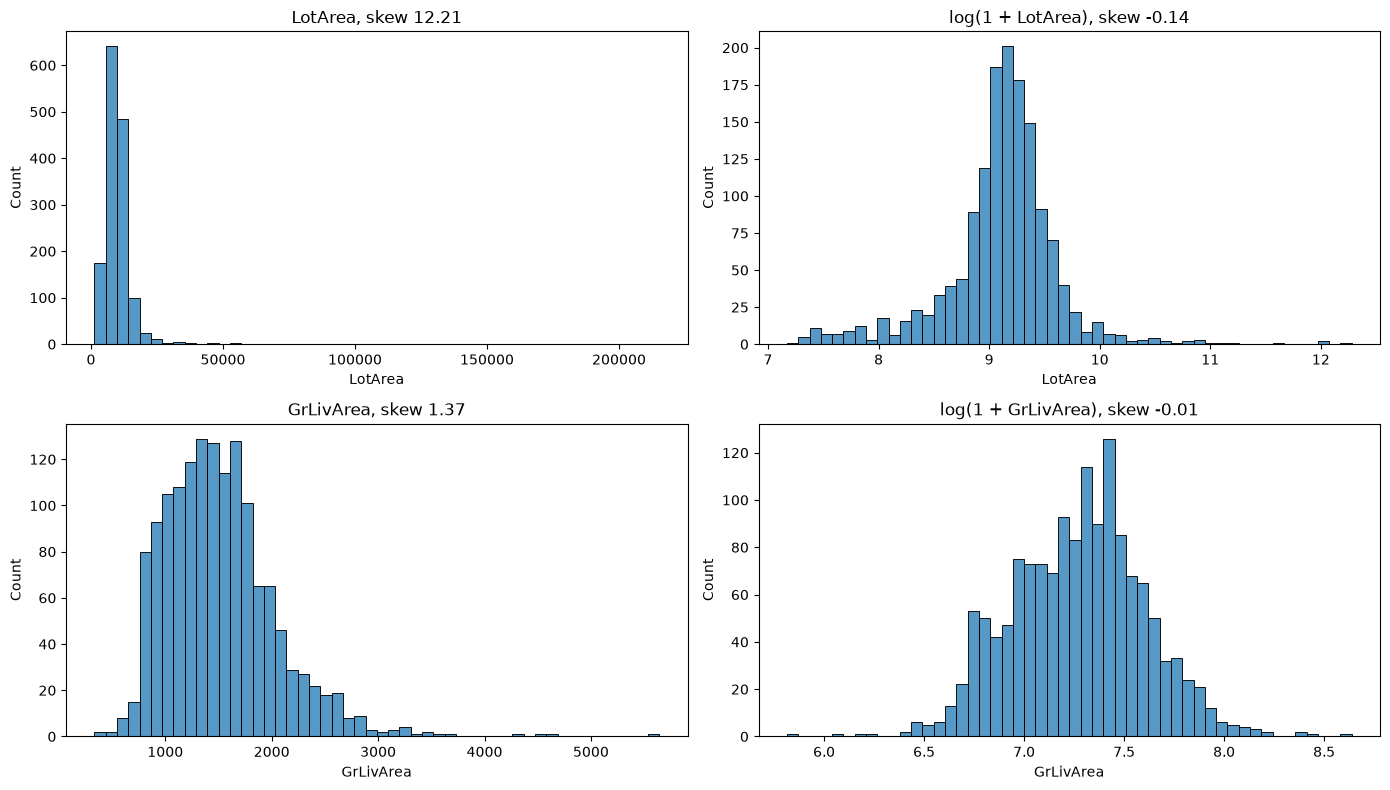

In [16]:
cols = ["LotArea", "GrLivArea"]

fig, axes = plt.subplots(2, 2, figsize=(14, 8))
for i, col in enumerate(cols):
    sns.histplot(train[col], bins=50, ax=axes[i, 0])
    axes[i, 0].set_title(f"{col}, skew {train[col].skew():.2f}")
    sns.histplot(np.log1p(train[col]), bins=50, ax=axes[i, 1])
    axes[i, 1].set_title(f"log(1 + {col}), skew {np.log1p(train[col]).skew():.2f}")
plt.tight_layout()
plt.show()

### Промежуточные выводы
- **Район (`Neighborhood`)** один из сильнейших признаков: медиана цены от 88 тыс. \$ (`MeadowV`) до 315 тыс. \$ (`NridgHt`).
- **Признаки качества** (`ExterQual`, `KitchenQual`, `BsmtQual`) дают ровную лесенку цены по шкале `Fa < TA < Gd < Ex`, поэтому их стоит кодировать числами по порядку. `GarageQual` и `HeatingQC` слабее: почти все дома в одной группе.
- **Почти константные:** `Utilities` (99.9% одно значение), `Street`, `PoolQC`, `Condition2`, `RoofMatl`, `Heating` (98–99.6%). Кандидаты на удаление.
- **Скошенные числовые** (skew > 0.75), три группы:
  - площади с длинным хвостом (`LotArea`, `GrLivArea`, `1stFlrSF`, `LotFrontage`, `MasVnrArea`, `OpenPorchSF`, `WoodDeckSF`, `BsmtFinSF1`, `2ndFlrSF`): `log1p` делает их почти симметричными (`LotArea` 12.2 → −0.14);
  - почти всегда 0 (`PoolArea`, `3SsnPorch`, `LowQualFinSF`, `MiscVal`, `ScreenPorch`, `EnclosedPorch`, `BsmtFinSF2`): логарифм не помогает, лучше флаг «есть / нет» или удаление;
  - счётчики и категории (`KitchenAbvGr`, `BsmtHalfBath`, `MSSubClass`): логарифм не нужен.

## Итоговый вывод для EDA
**Главное о данных:** 1460 домов в train, 1459 в test, 79 признаков (36 числовых, 43 категориальных). Цена скошена вправо (медиана 163 тыс. \$), после `log1p` почти симметрична. Сильнее всего на цену влияют общее качество `OverallQual`, жилая площадь `GrLivArea`, район `Neighborhood`, гараж, подвал и признаки качества (`ExterQual`, `KitchenQual`, `BsmtQual`).

**План предобработки:**
- **Таргет:** учим на `log1p(SalePrice)`, в сабмит `expm1`.
- **Пропуски «объекта нет»** (`PoolQC`, `MiscFeature`, `Alley`, `Fence`, `FireplaceQu`, `Garage*`, `Bsmt*`, `MasVnrType`): категориальные заполнить значением `"None"`, числовые (`GarageYrBlt`, `MasVnrArea` и площади подвала/гаража в test) нулём.
- **Настоящие пропуски:** `LotFrontage` медианой по району (`Neighborhood`), остальные единичные медианой / самым частым значением, как в Титанике.
- **Кодирование:** признаки качества (`Ex > Gd > TA > Fa > Po`) числами по порядку, остальные категории One-Hot. Сравнить с One-Hot для всех. `MSSubClass` перевести в категорию.
- **Скошенные площади** (`LotArea`, `GrLivArea`, `1stFlrSF`, `LotFrontage` и др.) в `log_numeric`.
- **Почти константные** (`Utilities`, `Street`, `PoolQC`, `Condition2`, `RoofMatl`, `Heating`) и почти всегда нулевые (`PoolArea`, `3SsnPorch`, `LowQualFinSF`, `MiscVal`) проверить на удаление.
- **Скоррелированные пары** (`GarageCars`–`GarageArea`, `YearBuilt`–`GarageYrBlt`, `GrLivArea`–`TotRmsAbvGrd`, `TotalBsmtSF`–`1stFlrSF`): проверить, оставить ли по одному.
- **Выбросы:** 2 огромных дешёвых дома (Id 524, 1299). Сравнить CV с ними и без них.

Каждое изменение оцениваем по CV до и после.